# The computational model → `stimulus_ring.pdf`, `model_equation.pdf`

Two standalone schematics, each its own PDF so they can be placed and scaled independently
when the figure is assembled.

1. **`stimulus_ring.pdf`** — the task's dashed stimulus ring with a fixation cross at its
   centre, and nothing else.
2. **`model_equation.pdf`** — the model, alone:

$$\text{Firing rate} \;=\; (1-\rho)\,\color{red}{F_{\mathrm{present}}} + \rho\,\int\color{green}{F_{\mathrm{future}}}$$

A relational neuron reports neither what is in its receptive field now nor purely what will
be there after the next saccade, but a mixture of the two. $\rho = 0$ is a purely
retinotopic neuron, $\rho = 1$ a purely predictive one. That $\rho$ plays the same role as
the relational-bias parameter fit to real neurons in `figure_relationality.ipynb`, but it
is not the same parameterisation: there, the parameter slides the *reference point* from
fixation to the midpoint of the pair.

**On the layout.** The line is assembled from separate mathtext pieces — the lead, then one
per term — because mathtext colours a whole text artist at once, so two differently coloured
terms have to be two artists. The code below measures each after a draw and places them
end to end.

In [1]:
import matplotlib.pyplot as plt

import numpy as np

import common

common.set_style()

FIGSIZE_RING = (1.8, 1.8)
FIGSIZE_EQUATION = (1.0, 0.15)

## The drawing code

Both panels are drawn here rather than in a library: they are two functions used by nothing
else, and reading them beside the figures they make is worth more than a file of their own.

The equation is

$$\text{Firing rate} = (1-\rho)\,F_\text{present} + \rho \int F_\text{future}$$

drawn with its two terms in different colours, which is the only reason it is not a single
mathtext string: **mathtext colours a whole text artist at once**. Each coloured term has to
be its own artist, so the line is assembled from pieces — each measured after a draw and
placed end to end, then shifted so the whole row is centred. A single centred string would
have given the centring for free; the colour is what costs it. The same mechanism gives each
piece its own size and vertical nudge, which the integral sign uses.

In [2]:
RED = (0.84, 0.11, 0.11)      # F_present ...
GREEN = (0.11, 0.58, 0.22)    # ... and F_future

#: The expression, as pieces. A piece is a bare mathtext string (drawn in `color`) or a
#: tuple `(text, colour, scale, dy)` whose last three entries are optional — `scale`
#: multiplies the font size and `dy` shifts the piece, both like the lead's own knobs.
#: `\boldsymbol` keeps the italic F that `\mathbf` would lose; `\mathbf` bolds the upright
#: subscript.
EQUATION_BODY = (
    r'(1-\rho)\,',
    (r'\boldsymbol{F}_{\mathbf{present}}', RED),
    r' + \rho\,',
    r'\int',
    (r'\boldsymbol{F}_{\mathbf{future}}', GREEN),
)

#: What the equation *is*, in front of the expression. Mathtext like everything else, so a
#: literal space does nothing — words are spaced with `\ `.
EQUATION_LEAD = r'\mathrm{Firing\ rate} ='


def ring_figure(figsize=(2.0, 2.0), radius=1.0, margin=0.12):
    """The dashed stimulus ring and its fixation cross, alone.

    The axis is equal-aspect and spineless, so the ring is a circle whatever the figure's
    shape and `bbox_inches='tight'` crops the rest; `margin` is the blank space around it,
    in ring radii.
    """
    fig, ax = plt.subplots(figsize=figsize)
    t = np.linspace(0, 2 * np.pi, 361)
    ax.plot(radius * np.cos(t), radius * np.sin(t), ls='--', color='k', lw=0.9, alpha=0.35)
    ax.plot([0], [0], marker='+', color='k', markersize=8, markeredgewidth=1.4)

    lim = radius * (1.0 + margin)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    return fig, ax


def _piece(seg, fontsize, color):
    """Normalise one body segment to `(mathtext, fontsize, dy, colour)`."""
    if isinstance(seg, str):
        seg = (seg,)
    text = seg[0]
    return (f'${text}$',
            fontsize * (seg[2] if len(seg) > 2 and seg[2] is not None else 1.0),
            seg[3] if len(seg) > 3 and seg[3] is not None else 0.0,
            seg[1] if len(seg) > 1 and seg[1] is not None else color)


def equation_figure(body=EQUATION_BODY, lead=EQUATION_LEAD, figsize=(1.0, 0.15),
                    fontsize=14, lead_gap=0.08, color='k'):
    """The equation on one line: `lead`, then the pieces of `body`, end to end.

    Widths are only known once a piece has been rendered, so everything is drawn at the
    origin, the figure is drawn once, and the pieces are then measured and repositioned.
    `lead_gap` is the space after the lead, in units of `fontsize`; the body's own pieces
    butt against each other, and are spaced from within by `\\,` and friends — a literal
    space between them would do nothing, since math mode ignores literal spaces.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis('off')

    pieces = [_piece(seg, fontsize, color) for seg in body]
    gaps = [0.0] * len(pieces)
    if lead:
        pieces.insert(0, (f'${lead}$', fontsize, 0.0, color))
        gaps = [0.0, lead_gap] + [0.0] * (len(pieces) - 2)

    texts = [ax.text(0.0, 0.5, t, fontsize=fs, color=c, ha='left', va='center',
                     transform=ax.transAxes) for t, fs, _, c in pieces]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_axes = ax.transAxes.inverted()

    def axes_width(t):
        bb = t.get_window_extent(renderer)
        return abs(to_axes.transform((bb.x1, 0))[0] - to_axes.transform((bb.x0, 0))[0])

    def axes_height(points):
        px = points * fig.dpi / 72.0
        return abs(to_axes.transform((0, px))[1] - to_axes.transform((0, 0))[1])

    widths = [axes_width(t) for t in texts]
    gaps = [g * axes_height(fontsize) for g in gaps]
    x = 0.5 - (sum(widths) + sum(gaps)) / 2
    for text, width, gap, (_, _, dy, _c) in zip(texts, widths, gaps, pieces):
        x += gap
        text.set_position((x, 0.5 + dy * axes_height(fontsize)))
        x += width
    return fig, ax

## The ring

Dashed ring, fixation cross, nothing else.

saved stimulus_ring.pdf


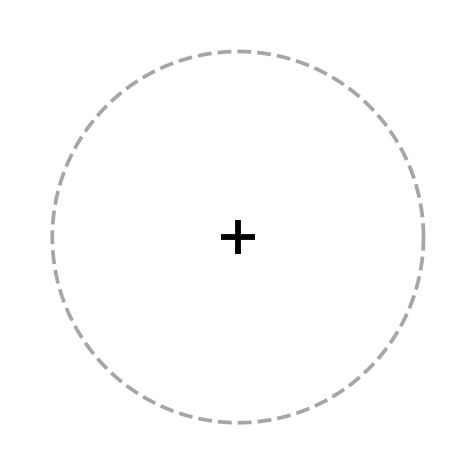

In [3]:
fig, _ = ring_figure(figsize=FIGSIZE_RING)
common.save(fig, 'stimulus_ring.pdf')
plt.show()

## The equation

The two terms carry their own colours; the integral sign is its own piece, so it can be sized and nudged independently of the rest.

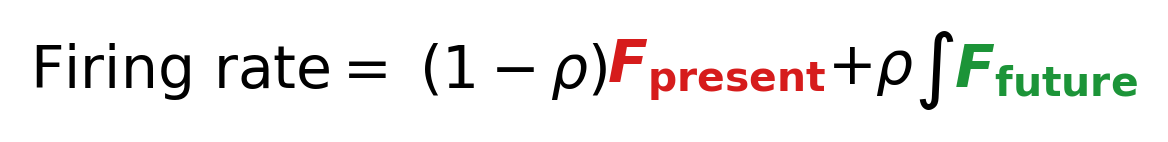

In [4]:
fig, _ = equation_figure(figsize=FIGSIZE_EQUATION)
# common.save(fig, 'model_equation.pdf')
plt.show()